# 04 · Feature Engineering and Preprocessing

**What this notebook covers**

- Create new features from existing columns (row by row, no leakage)
- Unit tests for the feature functions
- Define the two feature sets: `day_zero` and `full_lifecycle`
- Learn the ADR cap on Train only
- Build preprocessing templates for linear and tree models
- Check the templates on Train and Dev, with plots
- Save the feature files, templates, feature spec and feature log

## 1. Environment setup
### 1.1 Imports

In [1]:
import hashlib
import json
import platform
import sys
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

### 1.2 Configuration, seed and paths

In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

NOTEBOOK_PREFIX = "04"
ADR_CAP_QUANTILE = 0.995        # winsorisation quantile, learned on Train only (decision #8)
TOP_N_HIGH_CARDINALITY = 10     # keep the N most frequent country/agent/company levels, bucket the rest

# Resolve the repository root regardless of where the kernel was started
# (VS Code starts kernels in notebooks/, Jupyter may start them at the repo root).
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "docs" / "DECISIONS.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Project root not found (no DECISIONS.md in any parent directory).")


PROJECT_ROOT = find_project_root()

PATHS = {
    "raw": PROJECT_ROOT / "data" / "hotel_bookings.csv",
    "clean": PROJECT_ROOT / "data" / "interim" / "hotel_bookings_clean.csv",
    "splits": PROJECT_ROOT / "data" / "processed" / "splits",
    "features": PROJECT_ROOT / "data" / "processed" / "features",
    "artifacts": PROJECT_ROOT / "artifacts",
    "preprocessors": PROJECT_ROOT / "artifacts" / "preprocessors",
    "model_outputs": PROJECT_ROOT / "artifacts" / "model_outputs",
    "models": PROJECT_ROOT / "models",
    "figures": PROJECT_ROOT / "reports" / "figures",
    "tables": PROJECT_ROOT / "reports" / "tables",
    "notebooks": PROJECT_ROOT / "notebooks",
}
for key in ("artifacts", "preprocessors", "model_outputs", "models", "figures", "tables"):
    PATHS[key].mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")

Project root: /home/hasitha-erandika/Documents/Projects/hotel-booking-cancellation-ml


### 1.3 Shared constants, helpers and plotting style

In [3]:
# Columns that must always be treated as categorical strings when re-reading CSVs.
STRING_COLUMNS = [
    "hotel", "arrival_date_month", "meal", "country", "market_segment", "distribution_channel",
    "reserved_room_type", "assigned_room_type", "deposit_type", "agent", "company",
    "customer_type", "arrival_season",
]
TARGET = "is_canceled"
ID_COLUMN = "booking_id"
LEAKAGE_COLUMNS = ["reservation_status", "reservation_status_date"]

def sha256_file(path: Path, chunk_size: int = 1 << 20) -> str:
    """Streaming SHA-256 of a file (used to fingerprint every artifact)."""
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def save_json(obj: dict, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=str))


def load_json(path: Path) -> dict:
    if not path.exists():
        raise FileNotFoundError(f"Required artifact missing: {path.relative_to(PROJECT_ROOT)}")
    return json.loads(path.read_text())


def read_frame(path: Path) -> pd.DataFrame:
    """Read a project CSV with categorical columns forced to plain Python strings.

    `keep_default_na=False` + an explicit NA list stops pandas from turning legitimate
    category labels into NaN; numeric columns are parsed normally.
    """
    if not path.exists():
        raise FileNotFoundError(f"Required data file missing: {path.relative_to(PROJECT_ROOT)}")
    frame = pd.read_csv(
        path,
        dtype={col: object for col in STRING_COLUMNS},
        keep_default_na=False,
        na_values=["", "NaN", "nan"],
    )
    present = [c for c in STRING_COLUMNS if c in frame.columns]
    frame[present] = frame[present].astype(object)
    return frame

In [4]:
# One visual language for every figure in the project:
#  - blue = not cancelled, orange = cancelled (validated colour-blind-safe pair)
#  - single-series charts use blue; recessive grey grid; no top/right spines; no dual axes.
COLORS = {
    "not_canceled": "#2a78d6",
    "canceled": "#eb6834",
    "neutral": "#8a8985",
    "ink": "#0b0b0b",
    "ink_muted": "#52514e",
}
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQUENTIAL_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
DIVERGING_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_diverging", ["#2a78d6", "#e8e7e3", "#eb6834"]
)

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.prop_cycle": mpl.cycler(color=SERIES_COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.labelcolor": COLORS["ink_muted"],
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "axes.titlecolor": COLORS["ink"],
    "axes.grid": True,
    "grid.color": "#e8e7e3",
    "grid.linewidth": 0.8,
    "xtick.color": COLORS["ink_muted"],
    "ytick.color": COLORS["ink_muted"],
    "lines.linewidth": 2,
    "legend.frameon": False,
})


def save_figure(fig, name: str) -> Path:
    """Save a figure under reports/figures with this notebook's numeric prefix."""
    path = PATHS["figures"] / f"{NOTEBOOK_PREFIX}_{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved figure -> {path.relative_to(PROJECT_ROOT)}")
    return path

In [5]:
import importlib.metadata as importlib_metadata

def library_versions(packages=("numpy", "pandas", "scikit-learn", "xgboost", "matplotlib", "seaborn", "scipy", "shap", "joblib")) -> dict:
    versions = {"python": sys.version.split()[0], "platform": platform.platform()}
    for package in packages:
        try:
            versions[package] = importlib_metadata.version(package)
        except importlib_metadata.PackageNotFoundError:
            versions[package] = "not installed"
    return versions

LIBRARY_VERSIONS = library_versions()
pd.Series(LIBRARY_VERSIONS, name="version").to_frame()

,version
python,3.11.15
platform,Linux-7.0.0-38-generic-x86_64-with-glibc2.43
numpy,2.4.6
pandas,3.0.3
scikit-learn,1.9.0
xgboost,not installed
matplotlib,3.10.9
seaborn,0.13.2
scipy,1.17.1
shap,not installed


## 2. Load and verify the splits

In [6]:
split_manifest = load_json(PATHS["artifacts"] / "split_manifest.json")
splits = {}
for name in ("train", "dev", "test"):
    path = PATHS["splits"] / f"{name}.csv"
    assert sha256_file(path) == split_manifest["file_hashes"][name], f"{name} split changed - re-run notebook 02."
    splits[name] = read_frame(path)
    print(f"{name:>5}: {splits[name].shape}")

train: (60996, 31)
  dev: (13071, 31)
 test: (13071, 31)


## 3. Stateless feature engineering
### 3.1 Feature functions
Each feature is a small, named function, so it can be unit-tested and cited in the
feature log. None of them reads a statistic computed from other rows.

In [7]:
SEASON_BY_MONTH = {
    "December": "Winter", "January": "Winter", "February": "Winter",
    "March": "Spring", "April": "Spring", "May": "Spring",
    "June": "Summer", "July": "Summer", "August": "Summer",
    "September": "Autumn", "October": "Autumn", "November": "Autumn",
}


def add_stay_features(df):
    df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
    df["weekend_night_ratio"] = np.where(df["total_nights"] > 0, df["stays_in_weekend_nights"] / df["total_nights"].clip(lower=1), 0.0)
    return df


def add_party_features(df):
    df["total_guests"] = df["adults"] + df["children"] + df["babies"]
    df["is_family"] = ((df["children"] > 0) | (df["babies"] > 0)).astype(int)
    df["is_invalid_guest_count"] = (df["total_guests"] == 0).astype(int)
    return df


def add_history_features(df):
    df["total_previous_bookings"] = df["previous_cancellations"] + df["previous_bookings_not_canceled"]
    df["prior_cancellation_rate"] = np.where(
        df["total_previous_bookings"] > 0, df["previous_cancellations"] / df["total_previous_bookings"].clip(lower=1), 0.0
    )
    return df


def add_calendar_features(df):
    df["arrival_season"] = df["arrival_date_month"].map(SEASON_BY_MONTH).astype(object)
    return df


def add_lifecycle_features(df):
    # Room re-assignment usually happens at check-in -> full-lifecycle variant only (decision #6).
    df["room_type_changed"] = (df["reserved_room_type"] != df["assigned_room_type"]).astype(int)
    return df


FEATURE_FUNCTIONS = [add_stay_features, add_party_features, add_history_features,
                     add_calendar_features, add_lifecycle_features]


def engineer_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Apply every stateless feature function to a copy of the frame (row count unchanged)."""
    out = frame.copy()
    for function in FEATURE_FUNCTIONS:
        out = function(out)
    return out

### 3.2 Unit checks on hand-built edge cases
Small, explicit test rows cover the edge cases that matter: zero-night stays (division by
zero), no booking history, zero guests and room changes. These checks act as
notebook-level unit tests.

In [8]:
edge_cases = pd.DataFrame({
    "stays_in_weekend_nights": [0, 2, 1], "stays_in_week_nights": [0, 3, 0],
    "adults": [0, 2, 1], "children": [0, 1, 0], "babies": [0, 0, 1],
    "previous_cancellations": [0, 1, 3], "previous_bookings_not_canceled": [0, 3, 0],
    "arrival_date_month": ["January", "July", "October"],
    "reserved_room_type": ["A", "A", "D"], "assigned_room_type": ["A", "C", "D"],
})
engineered_cases = engineer_features(edge_cases)

assert engineered_cases["total_nights"].tolist() == [0, 5, 1]
assert engineered_cases["weekend_night_ratio"].tolist() == [0.0, 0.4, 1.0]
assert engineered_cases["total_guests"].tolist() == [0, 3, 2]
assert engineered_cases["is_family"].tolist() == [0, 1, 1]
assert engineered_cases["is_invalid_guest_count"].tolist() == [1, 0, 0]
assert engineered_cases["prior_cancellation_rate"].tolist() == [0.0, 0.25, 1.0]
assert engineered_cases["arrival_season"].tolist() == ["Winter", "Summer", "Autumn"]
assert engineered_cases["room_type_changed"].tolist() == [0, 1, 0]
assert len(engineered_cases) == len(edge_cases)
print("All feature unit checks passed.")
engineered_cases

All feature unit checks passed.


,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,arrival_date_month,reserved_room_type,assigned_room_type,total_nights,weekend_night_ratio,total_guests,is_family,is_invalid_guest_count,total_previous_bookings,prior_cancellation_rate,arrival_season,room_type_changed
0,0,0,0,0,0,0,0,January,A,A,0,0.0,0,0,1,0,0.00,Winter,0
1,2,3,2,1,0,1,3,July,A,C,5,0.4,3,1,0,4,0.25,Summer,1
2,1,0,1,0,1,3,0,October,D,D,1,1.0,2,1,0,3,1.00,Autumn,0


### 3.3 Apply the feature functions to every split
Because the functions are stateless, applying them per split is equivalent to applying
them before the split, and it cannot leak information between splits.

In [9]:
features = {name: engineer_features(frame) for name, frame in splits.items()}

for name, frame in features.items():
    assert len(frame) == len(splits[name]), f"Row count changed in {name}"
    assert frame[ID_COLUMN].equals(splits[name][ID_COLUMN]), f"Row order changed in {name}"
    numeric = frame.select_dtypes(include="number")
    assert np.isfinite(numeric.to_numpy(dtype=float)).all(), f"Non-finite engineered values in {name}"

ENGINEERED_FEATURES = sorted(set(features["train"].columns) - set(splits["train"].columns))
print(f"Engineered features ({len(ENGINEERED_FEATURES)}): {ENGINEERED_FEATURES}")
features["train"][ENGINEERED_FEATURES].describe().T.round(3)

Engineered features (9): ['arrival_season', 'is_family', 'is_invalid_guest_count', 'prior_cancellation_rate', 'room_type_changed', 'total_guests', 'total_nights', 'total_previous_bookings', 'weekend_night_ratio']


,count,mean,std,min,25%,50%,75%,max
is_family,60996.0,0.104,0.305,0.0,0.0,0.00,0.0,1.0
is_invalid_guest_count,60996.0,0.002,0.044,0.0,0.0,0.00,0.0,1.0
prior_cancellation_rate,60996.0,0.013,0.109,0.0,0.0,0.00,0.0,1.0
room_type_changed,60996.0,0.150,0.357,0.0,0.0,0.00,0.0,1.0
total_guests,60996.0,2.024,0.778,0.0,2.0,2.00,2.0,55.0
total_nights,60996.0,3.620,2.730,0.0,2.0,3.00,5.0,56.0
total_previous_bookings,60996.0,0.214,1.912,0.0,0.0,0.00,0.0,78.0
weekend_night_ratio,60996.0,0.263,0.281,0.0,0.0,0.25,0.4,1.0


### 3.4 Cancellation rate by engineered feature (Train)
A quick check that the new features carry signal. Each panel shows the cancellation rate per group. The dashed line is the overall Train rate.

In [ ]:
train_view = features["train"]
overall_rate = train_view[TARGET].mean()
views = {
    "Total nights": pd.cut(train_view["total_nights"], [-1, 0, 2, 4, 7, np.inf], labels=["0", "1-2", "3-4", "5-7", "8+"]),
    "Total guests": train_view["total_guests"].clip(upper=4).astype(int).astype(str).replace({"4": "4+"}),
    "Family booking": train_view["is_family"].map({0: "No", 1: "Yes"}),
    "Prior cancellation rate": pd.cut(train_view["prior_cancellation_rate"], [-0.01, 0, 0.5, 1],
                                      labels=["0", "up to 50%", "over 50%"]),
    "Arrival season": pd.Categorical(train_view["arrival_season"], ["Spring", "Summer", "Autumn", "Winter"], ordered=True),
    "Room type changed": train_view["room_type_changed"].map({0: "No", 1: "Yes"}),
}

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (title, groups) in zip(axes.ravel(), views.items()):
    rates = train_view.groupby(pd.Series(groups, index=train_view.index), observed=True)[TARGET].agg(["mean", "size"])
    bars = ax.bar(rates.index.astype(str), rates["mean"], color=COLORS["not_canceled"], width=0.6)
    ax.bar_label(bars, labels=[f"{r:.0%}\nn={n:,}" for r, n in zip(rates["mean"], rates["size"])],
                 padding=2, fontsize=8, color=COLORS["ink_muted"])
    ax.axhline(overall_rate, color=COLORS["neutral"], linestyle="--", linewidth=1.2)
    ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
    ax.set_ylim(0, max(rates["mean"].max(), overall_rate) * 1.35)
    ax.set_title(title, loc="left")
    ax.grid(axis="x", visible=False)
fig.suptitle("Cancellation rate by engineered feature (Train)", x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.tight_layout()
save_figure(fig, "engineered_feature_rates")
plt.show()

## 4. Feature specification (both variants)
### 4.1 Column roles
Every column is assigned a role **explicitly**. This fixes the legacy bug where
`room_type_changed` was silently dropped by `remainder="drop"` (plan I-04). Assertions
in §4.3 make the roles exhaustive.

In [10]:
NUMERIC_CORE = [
    "lead_time", "arrival_date_week_number", "arrival_date_day_of_month",
    "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
    "total_of_special_requests",
    "total_nights", "weekend_night_ratio", "total_guests", "is_family", "is_invalid_guest_count",
    "total_previous_bookings", "prior_cancellation_rate",
]
ADR_COLUMN = ["adr"]
CATEGORICAL_LOW = ["hotel", "meal", "market_segment", "distribution_channel", "deposit_type",
                   "customer_type", "arrival_season", "reserved_room_type"]
CATEGORICAL_HIGH = ["country", "agent", "company"]

# Fields that accumulate after booking creation -> full-lifecycle variant only.
POST_BOOKING_NUMERIC = ["booking_changes", "days_in_waiting_list", "required_car_parking_spaces", "room_type_changed"]
POST_BOOKING_CATEGORICAL = ["assigned_room_type"]

EXCLUDED_COLUMNS = {
    ID_COLUMN: "Identifier, not a feature",
    TARGET: "Target",
    "arrival_date_year": "Non-stationary (drift 2015->2017); cannot extrapolate to future years (proposed decision #23)",
    "arrival_date_month": "Replaced by arrival_season + arrival_date_week_number",
    **{c: "Target leakage (decisions #3, #20) - already dropped in notebook 01" for c in LEAKAGE_COLUMNS},
}

VARIANTS = {
    "day_zero": {
        "numeric": NUMERIC_CORE,
        "adr": ADR_COLUMN,
        "categorical_low": CATEGORICAL_LOW,
        "categorical_high": CATEGORICAL_HIGH,
    },
    "full_lifecycle": {
        "numeric": NUMERIC_CORE + POST_BOOKING_NUMERIC,
        "adr": ADR_COLUMN,
        "categorical_low": CATEGORICAL_LOW + POST_BOOKING_CATEGORICAL,
        "categorical_high": CATEGORICAL_HIGH,
    },
}
{variant: sum(len(cols) for cols in spec.values()) for variant, spec in VARIANTS.items()}

{'day_zero': 31, 'full_lifecycle': 36}

### 4.2 Learn the ADR cap on Train only
The 99.5th-percentile cap (decision #8) is the only distribution-dependent value set
outside the pipeline. It is learned on Train and stored in the spec. Caveat (plan I-19):
CV folds inside Train share this one cap. The effect of a single quantile over ~61K
rows is negligible, and it is documented rather than hidden.

In [11]:
ADR_CAP = float(features["train"]["adr"].quantile(ADR_CAP_QUANTILE))
n_capped = {name: int((frame["adr"] > ADR_CAP).sum()) for name, frame in features.items()}
print(f"ADR cap (Train {ADR_CAP_QUANTILE:.1%} quantile): {ADR_CAP:.2f}")
print(f"Rows above the cap per split: {n_capped}")

ADR cap (Train 99.5% quantile): 283.68
Rows above the cap per split: {'train': 305, 'dev': 71, 'test': 81}


### 4.3 Contract assertions on the specification
- No leakage column or target appears in any variant.
- Day-zero contains none of the post-booking fields.
- Every available column is either used by some variant or explicitly excluded.
- Every engineered feature is consumed by at least one variant.

In [12]:
available_columns = set(features["train"].columns)
for variant, spec in VARIANTS.items():
    used = [c for cols in spec.values() for c in cols]
    assert len(used) == len(set(used)), f"{variant}: a column is assigned to two roles"
    assert not set(used) & (set(LEAKAGE_COLUMNS) | {TARGET, ID_COLUMN}), f"{variant}: leakage/target in features"
    missing = set(used) - available_columns
    assert not missing, f"{variant}: columns not found {missing}"

day_zero_used = {c for cols in VARIANTS["day_zero"].values() for c in cols}
assert not day_zero_used & set(POST_BOOKING_NUMERIC + POST_BOOKING_CATEGORICAL), "Post-booking field in day_zero"

all_used = {c for spec in VARIANTS.values() for cols in spec.values() for c in cols}
unassigned = available_columns - all_used - set(EXCLUDED_COLUMNS)
assert not unassigned, f"Columns with no role: {unassigned}"
assert set(ENGINEERED_FEATURES) <= all_used, f"Engineered but unused: {set(ENGINEERED_FEATURES) - all_used}"
print("Feature-spec contract assertions passed.")

Feature-spec contract assertions passed.


## 5. Preprocessing templates (sklearn-native only)
### 5.1 Builder
Two preprocessing **families**:

| Family | Used by | Numeric treatment |
|---|---|---|
| `linear` | Dummy, Logistic Regression, SVM | median impute → `StandardScaler` (distance/gradient based) |
| `tree` | Decision Tree, Random Forest, XGBoost | median impute only (splits are scale-invariant) |

Shared parts:

- **ADR:** median impute → `FunctionTransformer(np.clip)` at the Train cap.
- **Low-cardinality categoricals:** one-hot with `handle_unknown="ignore"`.
- **High-cardinality** (`country`, `agent`, `company`): one-hot with
  `max_categories=TOP_N+1`. This is the native replacement for the legacy `TopNBucketer`.
  Rare and unseen levels go into a single "infrequent" column.

Dense output (`sparse_output=False`) keeps SHAP and coefficient analysis simple at ~100 columns.

In [13]:
def build_preprocessor(variant: str, family: str) -> ColumnTransformer:
    if family not in {"linear", "tree"}:
        raise ValueError(f"Unknown family {family!r}")
    spec = VARIANTS[variant]
    scale = family == "linear"

    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    adr_steps = [
        ("impute", SimpleImputer(strategy="median")),
        ("winsorize", FunctionTransformer(np.clip, kw_args={"a_min": 0.0, "a_max": ADR_CAP}, feature_names_out="one-to-one")),
    ]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
        adr_steps.append(("scale", StandardScaler()))

    categorical_low = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    categorical_high = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", max_categories=TOP_N_HIGH_CARDINALITY + 1,
                                 sparse_output=False)),
    ])

    return ColumnTransformer(
        transformers=[
            ("num", Pipeline(numeric_steps), spec["numeric"]),
            ("adr", Pipeline(adr_steps), spec["adr"]),
            ("cat_low", categorical_low, spec["categorical_low"]),
            ("cat_high", categorical_high, spec["categorical_high"]),
        ],
        remainder="drop",            # safe: every column's role is asserted in section 4.3
        verbose_feature_names_out=True,
    )


TEMPLATES = {(variant, family): build_preprocessor(variant, family)
             for variant in VARIANTS for family in ("linear", "tree")}
list(TEMPLATES)

[('day_zero', 'linear'),
 ('day_zero', 'tree'),
 ('full_lifecycle', 'linear'),
 ('full_lifecycle', 'tree')]

### 5.2 Fit on Train only, transform Dev (validation of the templates)
This demonstrates the leakage-safe contract: `.fit` sees Train, Dev only goes through
`.transform`. The fitted copies are used here for checks only. The saved templates stay
unfitted.

In [14]:
X_train = features["train"].drop(columns=[TARGET, ID_COLUMN])
X_dev = features["dev"].drop(columns=[TARGET, ID_COLUMN])

fitted, shapes = {}, []
for key, template in TEMPLATES.items():
    pre = clone(template).fit(X_train)
    train_matrix, dev_matrix = pre.transform(X_train), pre.transform(X_dev)
    assert np.isfinite(train_matrix).all() and np.isfinite(dev_matrix).all(), f"Non-finite output for {key}"
    assert train_matrix.shape[1] == dev_matrix.shape[1] == len(pre.get_feature_names_out()), f"Width mismatch for {key}"
    fitted[key] = pre
    shapes.append({"variant": key[0], "family": key[1], "n_output_features": train_matrix.shape[1],
                   "train_rows": train_matrix.shape[0], "dev_rows": dev_matrix.shape[0]})
pd.DataFrame(shapes)

,variant,family,n_output_features,train_rows,dev_rows
0,day_zero,linear,94,60996,13071
1,day_zero,tree,94,60996,13071
2,full_lifecycle,linear,109,60996,13071
3,full_lifecycle,tree,109,60996,13071


#### Model input width per preprocessing block
How many output columns each block produces. One-hot encoding of the categorical columns makes up most of the width.

In [ ]:
block_counts = pd.DataFrame({
    f"{variant} / {family}": pd.Series(pre.get_feature_names_out()).str.split("__").str[0].value_counts()
    for (variant, family), pre in fitted.items()
}).fillna(0).T[["num", "adr", "cat_low", "cat_high"]]

fig, ax = plt.subplots(figsize=(9, 3.6))
left = np.zeros(len(block_counts))
for color, block in zip(SERIES_COLORS, block_counts.columns):
    ax.barh(block_counts.index, block_counts[block], left=left, color=color, height=0.55, label=block)
    left += block_counts[block].to_numpy()
for y, total in enumerate(left):
    ax.text(total + 1, y, f"{int(total)}", va="center", color=COLORS["ink_muted"], fontsize=9)
ax.set_xlim(0, left.max() * 1.12)
ax.set_xlabel("Output columns after preprocessing")
ax.set_title("Model input width by preprocessing block", loc="left")
ax.legend(ncol=4, loc="lower right", bbox_to_anchor=(1, 1.02))
ax.grid(axis="y", visible=False)
save_figure(fig, "output_width_by_block")
plt.show()

### 5.3 Verify the scaler and encoders learned from Train only
A fitted `StandardScaler` records how many rows it saw. That count must equal the Train
size. The same check is repeated independently by the validation gate (notebook 10).

In [15]:
linear_pre = fitted[("day_zero", "linear")]
scaler = linear_pre.named_transformers_["num"].named_steps["scale"]
assert scaler.n_samples_seen_ == len(X_train), "Scaler saw a different number of rows than Train."
high_card_categories = linear_pre.named_transformers_["cat_high"].named_steps["onehot"].categories_
print(f"Scaler fitted on {int(scaler.n_samples_seen_):,} rows (= Train).")
print({col: len(cats) for col, cats in zip(CATEGORICAL_HIGH, high_card_categories)}, "levels seen in Train")

Scaler fitted on 60,996.0 rows (= Train).
{'country': 164, 'agent': 314, 'company': 317} levels seen in Train


### 5.4 Unseen-category robustness
Dev contains category levels Train never saw (rare countries or agents). They must
transform without error: the low-cardinality encoder ignores them and the
high-cardinality encoder maps them to the infrequent bucket.

In [16]:
unseen = {col: sorted(set(X_dev[col]) - set(X_train[col]))[:5] for col in CATEGORICAL_LOW + CATEGORICAL_HIGH
          if set(X_dev[col]) - set(X_train[col])}
print("Examples of Dev-only category levels:", unseen or "none")
_ = fitted[("full_lifecycle", "tree")].transform(X_dev)
print("Dev transformed successfully despite unseen levels.")

Examples of Dev-only category levels: {'country': ['ABW', 'ATF', 'BDI', 'CYM', 'DMA'], 'agent': ['167', '197', '267', '291', '294'], 'company': ['168', '212', '278', '288', '313']}
Dev transformed successfully despite unseen levels.


### 5.5 Output feature names
Native encoders keep feature names end-to-end. Explainability (notebook 13) depends on
this.

In [17]:
names = fitted[("full_lifecycle", "tree")].get_feature_names_out()
print(f"{len(names)} output features, e.g.:")
pd.Series(names).groupby(pd.Series(names).str.split("__").str[0]).head(4).to_frame("feature_name")

109 output features, e.g.:


,feature_name
0,num__lead_time
1,num__arrival_date_week_number
2,num__arrival_date_day_of_month
3,num__stays_in_weekend_nights
23,adr__adr
24,cat_low__hotel_City Hotel
25,cat_low__hotel_Resort Hotel
26,cat_low__meal_BB
27,cat_low__meal_FB
76,cat_high__country_BEL


### 5.6 Before / after view of the ADR treatment
One shared y-axis scale per panel: raw ADR on Train next to the winsorised values, to
show the cap only affects the extreme tail.

Saved figure -> reports/figures/04_adr_before_after.png


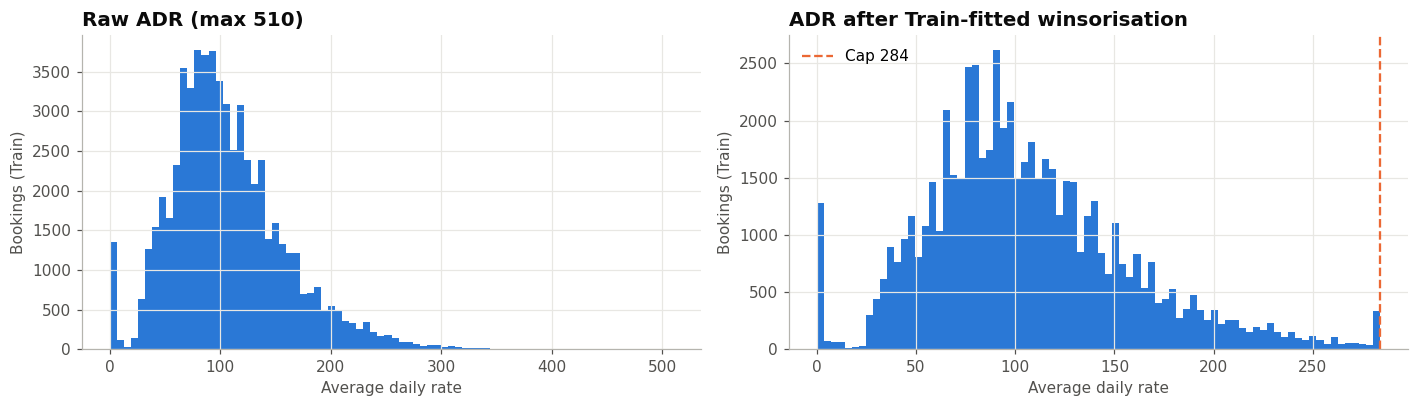

In [18]:
adr_after = fitted[("day_zero", "tree")].named_transformers_["adr"].transform(X_train[["adr"]]).ravel()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(X_train["adr"], bins=80, color=COLORS["not_canceled"])
axes[0].set_title(f"Raw ADR (max {X_train['adr'].max():,.0f})", loc="left")
axes[1].hist(adr_after, bins=80, color=COLORS["not_canceled"])
axes[1].axvline(ADR_CAP, color=COLORS["canceled"], linestyle="--", linewidth=1.5, label=f"Cap {ADR_CAP:.0f}")
axes[1].set_title("ADR after Train-fitted winsorisation", loc="left")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("Average daily rate")
    ax.set_ylabel("Bookings (Train)")
fig.tight_layout()
save_figure(fig, "adr_before_after")
plt.show()

## 6. Persist artifacts
### 6.1 Engineered feature files
These are the only data files model notebooks read (Train and Dev). The Test feature
file is read only by notebook 14.

In [19]:
PATHS["features"].mkdir(parents=True, exist_ok=True)
feature_file_hashes = {}
for name, frame in features.items():
    path = PATHS["features"] / f"{name}.csv"
    frame.to_csv(path, index=False)
    feature_file_hashes[name] = sha256_file(path)
feature_file_hashes

{'train': '3004a51b2c6dc9daacfc7dba80002af6d58ff38755b09d41d3c6518e3fa0e5f3',
 'dev': '52bc57213a77f0f4fbc3334d725bc1f4aa0a639dfa36dc15cecb0bc6a9a446a3',
 'test': '82adb2a27e52b63cce172d2d978d1d15a2554f2711e070b8dae7559293dce38e'}

### 6.2 Unfitted preprocessing templates + pickle round-trip test
Saving and re-loading proves the templates are portable across notebooks. This fixes
the legacy lambda problem (plan I-05).

In [20]:
template_paths = {}
for (variant, family), template in TEMPLATES.items():
    path = PATHS["preprocessors"] / f"preprocessor__{family}__{variant}.joblib"
    joblib.dump(template, path)
    reloaded = joblib.load(path)
    reloaded_out = clone(reloaded).fit(X_train).transform(X_dev)
    assert np.allclose(reloaded_out, fitted[(variant, family)].transform(X_dev)), f"Round-trip mismatch for {path.name}"
    template_paths[f"{family}__{variant}"] = str(path.relative_to(PROJECT_ROOT))
print("All templates saved and verified by joblib round-trip:")
template_paths

All templates saved and verified by joblib round-trip:


{'linear__day_zero': 'artifacts/preprocessors/preprocessor__linear__day_zero.joblib',
 'tree__day_zero': 'artifacts/preprocessors/preprocessor__tree__day_zero.joblib',
 'linear__full_lifecycle': 'artifacts/preprocessors/preprocessor__linear__full_lifecycle.joblib',
 'tree__full_lifecycle': 'artifacts/preprocessors/preprocessor__tree__full_lifecycle.joblib'}

### 6.3 Feature specification contract

In [21]:
feature_spec = {
    "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "notebook": "04_feature_engineering_preprocessing.ipynb",
    "source_split_hashes": split_manifest["file_hashes"],
    "file_hashes": feature_file_hashes,
    "target": TARGET,
    "id_column": ID_COLUMN,
    "variants": VARIANTS,
    "post_booking_columns": POST_BOOKING_NUMERIC + POST_BOOKING_CATEGORICAL,
    "leakage_columns": LEAKAGE_COLUMNS,
    "excluded_columns": EXCLUDED_COLUMNS,
    "engineered_features": ENGINEERED_FEATURES,
    "adr_cap": {"value": ADR_CAP, "quantile": ADR_CAP_QUANTILE, "fitted_on": "train"},
    "top_n_high_cardinality": TOP_N_HIGH_CARDINALITY,
    "preprocessor_templates": template_paths,
    "families": {"linear": ["dummy", "logreg", "svm_rbf"], "tree": ["decision_tree", "random_forest", "xgboost"]},
    "library_versions": LIBRARY_VERSIONS,
}
save_json(feature_spec, PATHS["artifacts"] / "feature_spec.json")
print("Feature spec -> artifacts/feature_spec.json")

Feature spec -> artifacts/feature_spec.json


### 6.4 Feature log
The rubric-facing table: every input feature with its origin, type, treatment, variant
membership and rationale. It is generated from the spec, so it cannot drift from the
code.

In [22]:
RATIONALE = {
    "total_nights": "Stay length as one business quantity",
    "weekend_night_ratio": "Leisure vs business-shaped stays",
    "total_guests": "Party size in one measure",
    "is_family": "Interpretable segment flag",
    "is_invalid_guest_count": "Flags 0-guest bookings instead of deleting them (docs/04 section 4.4)",
    "total_previous_bookings": "Denominator for history rate",
    "prior_cancellation_rate": "Strongest history signal as a rate",
    "arrival_season": "12 months -> 4 seasons",
    "room_type_changed": "Room re-assignment flag (full-lifecycle only)",
    "required_car_parking_spaces": "Probable arrival-time field (0% cancellation) - full-lifecycle only",
    "booking_changes": "Accumulates after booking - full-lifecycle only",
    "days_in_waiting_list": "Accumulates after booking - full-lifecycle only",
    "assigned_room_type": "Known near arrival - full-lifecycle only",
    "adr": f"Winsorised at Train {ADR_CAP_QUANTILE:.1%} quantile ({ADR_CAP:.0f})",
    "country": f"Top-{TOP_N_HIGH_CARDINALITY} one-hot + infrequent bucket; 'Unknown' for missing",
    "agent": f"Top-{TOP_N_HIGH_CARDINALITY} one-hot + infrequent bucket; 'No Agent' for missing",
    "company": f"Top-{TOP_N_HIGH_CARDINALITY} one-hot + infrequent bucket; 'No Company' for missing",
}

rows = []
role_of = {}
for variant, spec in VARIANTS.items():
    for role, columns in spec.items():
        for column in columns:
            role_of.setdefault(column, role)
for column, role in role_of.items():
    rows.append({
        "feature": column,
        "origin": "engineered" if column in ENGINEERED_FEATURES else "original",
        "role": role,
        "treatment_linear": {"numeric": "median impute + standardise", "adr": "impute + cap + standardise",
                             "categorical_low": "one-hot", "categorical_high": "top-N one-hot"}[role],
        "treatment_tree": {"numeric": "median impute", "adr": "impute + cap",
                           "categorical_low": "one-hot", "categorical_high": "top-N one-hot"}[role],
        "in_day_zero": column in day_zero_used,
        "in_full_lifecycle": True,
        "rationale": RATIONALE.get(column, ""),
    })
for column, reason in EXCLUDED_COLUMNS.items():
    rows.append({"feature": column, "origin": "original", "role": "excluded", "treatment_linear": "-",
                 "treatment_tree": "-", "in_day_zero": False, "in_full_lifecycle": False, "rationale": reason})

feature_log = pd.DataFrame(rows)
feature_log.to_csv(PATHS["tables"] / "feature_log.csv", index=False)
feature_log

,feature,origin,role,treatment_linear,treatment_tree,in_day_zero,in_full_lifecycle,rationale
0,lead_time,original,numeric,median impute + standardise,median impute,True,True,
1,arrival_date_week_number,original,numeric,median impute + standardise,median impute,True,True,
2,arrival_date_day_of_month,original,numeric,median impute + standardise,median impute,True,True,
3,stays_in_weekend_nights,original,numeric,median impute + standardise,median impute,True,True,
4,stays_in_week_nights,original,numeric,median impute + standardise,median impute,True,True,
5,adults,original,numeric,median impute + standardise,median impute,True,True,
6,children,original,numeric,median impute + standardise,median impute,True,True,
7,babies,original,numeric,median impute + standardise,median impute,True,True,
8,is_repeated_guest,original,numeric,median impute + standardise,median impute,True,True,
9,previous_cancellations,original,numeric,median impute + standardise,median impute,True,True,


## 7. Hand-off summary
- **For notebooks 05 to 09:** load `artifacts/preprocessors/preprocessor__<family>__<variant>.joblib`,
  wrap it with your estimator in a `Pipeline([("preprocess", ...), ("model", ...)])` and
  fit on Train only. Never re-implement encoding.
- **For notebook 10:** `feature_spec.json` is the reference the validation gate
  uses to check leakage columns and variant integrity.
- Append the feature log (§6.4) to `docs/04` and add proposed decisions **#22/#23** to `DECISIONS.md`.